# Burned area in West Kalimantan

**What this notebook has so far**
1. Loads the West Kalimantan province outline.
2. For each monthly burned-area file, counts the burned pixels inside that outline
   and converts them to hectares.
3. Saves a year x month table and shows a map of the burned area.

In [1]:
import os, re, glob

import numpy as np
import pandas as pd
import geopandas as gpd            # reads the province boundary
import rasterio                    # reads the .tif files
import matplotlib.pyplot as plt
from rasterio.windows import from_bounds, Window
from rasterio.features import geometry_mask


In [2]:
# Everything lives in Downloads, so the other paths are built from this one.
DOWNLOADS = "/Users/irinavardapetyan/Downloads"

# Province outline (the full-resolution one, not "_simplified")
boundary_file = f"{DOWNLOADS}/geoBoundaries-IDN-ADM1-all/geoBoundaries-IDN-ADM1.geojson"

# All monthly burned-area files, e.g. monthly_burned-indonesia_2026_01.tif
# (if you move the 2015-2021 files into a subfolder, add it here: f"{DOWNLOADS}/mapbiomas_fire/...")
fire_files = sorted(glob.glob(f"{DOWNLOADS}/monthly_burned-indonesia_*.tif"))
print(f"Found {len(fire_files)} burned-area file(s)")


Found 1 burned-area file(s)


In [3]:
provinces = gpd.read_file(boundary_file)                      # all 34 Indonesian provinces
wk = provinces[provinces["shapeName"] == "West Kalimantan"]   # keep just one
wk = wk.to_crs("EPSG:4326")                                   # lon/lat, same as the .tif files
assert len(wk) == 1, "Province name didn't match; print provinces['shapeName'] to see the options"
print("Bounds (min lon, min lat, max lon, max lat):", wk.total_bounds)


Bounds (min lon, min lat, max lon, max lat): [108.5990561  -3.0419035 114.206948    2.0814049]


In [4]:
def inspect_raster(fp):
    """Print the file's metadata only. Never reads pixels, so it is safe on huge files."""
    with rasterio.open(fp) as src:
        print("File size (GB):", round(os.path.getsize(fp) / 1e9, 2))
        print("CRS:           ", src.crs)            # coordinate system
        print("Pixel size:    ", src.res)            # in degrees (~8.98e-05 deg = ~10 m)
        print("Shape:         ", src.shape)          # rows, columns
        print("Bands:         ", src.count)          # 1 = a single layer (here: one month)
        print("Nodata value:  ", src.nodata)         # 0 here, so unburned pixels count as 'missing'
        print("Bounds:        ", src.bounds)

inspect_raster(fire_files[0])


File size (GB): 0.15
CRS:            EPSG:4326
Pixel size:     (8.983152841195215e-05, 8.983152841195215e-05)
Shape:          (193902, 525410)
Bands:          1
Nodata value:   0.0
Bounds:         BoundingBox(left=93.95192095715157, bottom=-10.033822397501407, right=141.15030430007533, top=7.384690624632938)


In [5]:
def burned_ha(fp, province, rows_per_strip=2048):
    """
    Count burned pixels (value 1) that fall inside the province polygon.

    The raster is too big to load at once (~100 billion pixels), so we:
      - only look at the province's bounding box, and
      - read it in horizontal strips, one at a time.
    """
    shapes = list(province.geometry)
    PIXEL_HA = 0.01          # one ~10 m x 10 m pixel = 0.01 hectares

    with rasterio.open(fp) as src:
        assert src.crs.to_epsg() == 4326, "File isn't in lon/lat; reproject the province first"

        # Rectangle around the province, converted to row/column positions in the raster
        win = from_bounds(*province.total_bounds, transform=src.transform)
        first_row, first_col = int(np.floor(win.row_off)), int(np.floor(win.col_off))
        n_rows, n_cols = int(np.ceil(win.height)) + 1, int(np.ceil(win.width)) + 1

        burned_pixels = 0
        for r in range(0, n_rows, rows_per_strip):
            # Read one strip of the bounding box
            strip = Window(first_col, first_row + r, n_cols, min(rows_per_strip, n_rows - r))
            pixels = src.read(1, window=strip, boundless=True, fill_value=0)

            if not pixels.any():          # nothing burned in this strip, skip it
                continue

            # True where a pixel is inside the province outline (the box includes
            # some area outside it, e.g. Sarawak and the sea)
            inside = geometry_mask(shapes, out_shape=pixels.shape,
                                   transform=src.window_transform(strip), invert=True)

            burned_pixels += int(((pixels == 1) & inside).sum())

    return burned_pixels * PIXEL_HA


In [6]:
results_csv = "monthly_burned_wk.csv"    # saved in the notebook's folder

# Load earlier results if they exist, so finished months are not recomputed
if os.path.exists(results_csv):
    rows = pd.read_csv(results_csv).to_dict("records")
else:
    rows = []
already_done = {(int(r["year"]), int(r["month"])) for r in rows}

for fp in fire_files:
    # Pull year and month out of the filename, e.g. ..._2026_01.tif -> 2026, 1
    match = re.search(r"_(\d{4})_(\d{2})\.tif$", fp)
    if not match:
        print("Skipping (unexpected filename):", os.path.basename(fp))
        continue
    year, month = int(match[1]), int(match[2])

    if (year, month) in already_done:
        continue

    ha = burned_ha(fp, wk)
    rows.append({"year": year, "month": month, "burned_ha": ha})
    pd.DataFrame(rows).to_csv(results_csv, index=False)   # save after every file
    print(f"{year}-{month:02d}: {ha:,.1f} ha")


In [7]:
monthly = pd.DataFrame(rows).sort_values(["year", "month"])
print(monthly.pivot(index="year", columns="month", values="burned_ha").round(0))
print()
print(monthly.groupby("year")["burned_ha"].sum().round(0).rename("total ha per year"))


month       1
year         
2026   1055.0

year
2026    1055.0
Name: total ha per year, dtype: float64


## Visual check: what is inside a tiff?


In [8]:
def preview(fp, province, target_size=1500):
    """
    Shrink the province's area to ~1500 x 1500 cells for plotting.

    Each cell takes the MAX of the pixels it covers (not the average), so a single
    burned pixel still shows up. Plain downsampling would miss most burned pixels
    and give a blank map. The cost: burned areas look bigger than they really are.
    """
    with rasterio.open(fp) as src:
        win = from_bounds(*province.total_bounds, transform=src.transform)
        first_row, first_col = int(np.floor(win.row_off)), int(np.floor(win.col_off))
        n_rows, n_cols = int(np.ceil(win.height)) + 1, int(np.ceil(win.width)) + 1

        block = int(np.ceil(max(n_rows, n_cols) / target_size))   # pixels per preview cell
        padded_cols = int(np.ceil(n_cols / block)) * block        # make width a multiple of block
        rows_per_strip = block * 64

        pieces = []
        for r in range(0, n_rows, rows_per_strip):
            h = min(rows_per_strip, n_rows - r)
            a = src.read(1, window=Window(first_col, first_row + r, padded_cols, h),
                         boundless=True, fill_value=0)
            a = np.pad(a, ((0, (-h) % block), (0, 0)))             # make height a multiple of block
            # Group pixels into block x block squares and take the max of each
            pieces.append(a.reshape(a.shape[0] // block, block,
                                    padded_cols // block, block).max(axis=(1, 3)))
        small = np.vstack(pieces)

        # Map extent (lon/lat edges) so the preview lines up with the province outline
        t = src.transform
        left = t.c + first_col * t.a
        right = left + small.shape[1] * block * t.a
        top = t.f + first_row * t.e                  # t.e is negative (rows go down)
        bottom = top + small.shape[0] * block * t.e
    return small, (left, right, bottom, top)


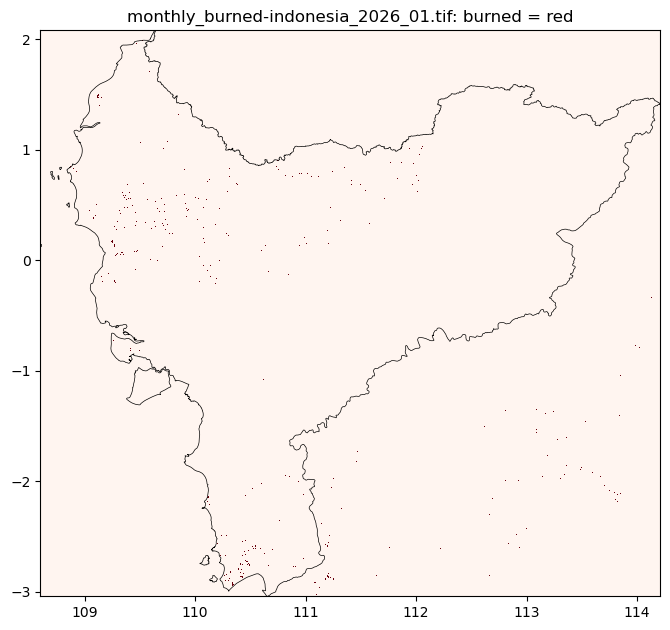

In [9]:
fp = fire_files[0]                      # change this to look at a different file
small, extent = preview(fp, wk)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(small, cmap="Reds", extent=extent, interpolation="nearest")
wk.boundary.plot(ax=ax, color="black", linewidth=0.5)          # province outline
ax.set_title(f"{os.path.basename(fp)}: burned = red")
plt.show()


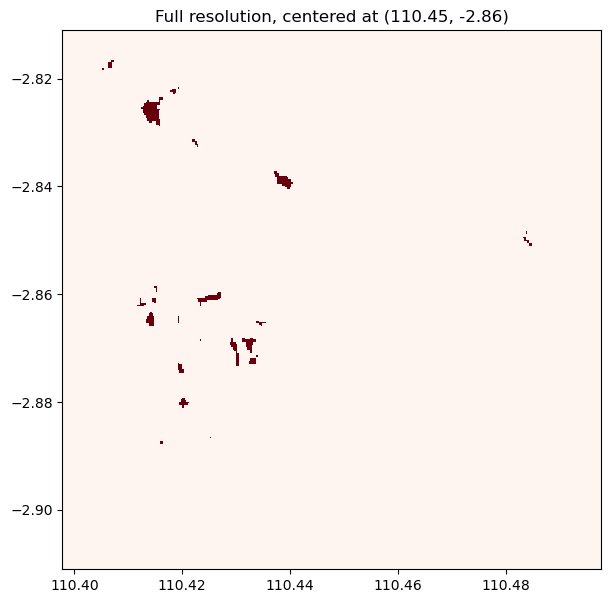

In [10]:
if small.any():
    H, W = small.shape
    # Slide over the preview in 20 x 20 squares and find the one with the most burned cells
    _, y0, x0 = max((small[y:y+20, x:x+20].sum(), y, x)
                    for y in range(0, H, 20) for x in range(0, W, 20))
    left, right, bottom, top = extent
    center_lon = left + (x0 + 10) / W * (right - left)
    center_lat = top - (y0 + 10) / H * (top - bottom)
    box = (center_lon - 0.05, center_lat - 0.05, center_lon + 0.05, center_lat + 0.05)

    with rasterio.open(fp) as src:
        zoomed = src.read(1, window=from_bounds(*box, transform=src.transform))

    plt.figure(figsize=(7, 7))
    plt.imshow(zoomed, cmap="Reds", extent=(box[0], box[2], box[1], box[3]),
               interpolation="nearest")
    plt.title(f"Full resolution, centered at ({center_lon:.2f}, {center_lat:.2f})")
    plt.show()
else:
    print("No burned pixels in this province for this file")
